In [3]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense , Flatten


In [6]:
(x_train , y_train) , (x_test , y_test) = keras.datasets.mnist.load_data()

In [10]:
x_train.shape

(60000, 28, 28)

In [12]:
x_test.shape

(10000, 28, 28)

In [14]:
y_train .shape

(60000,)

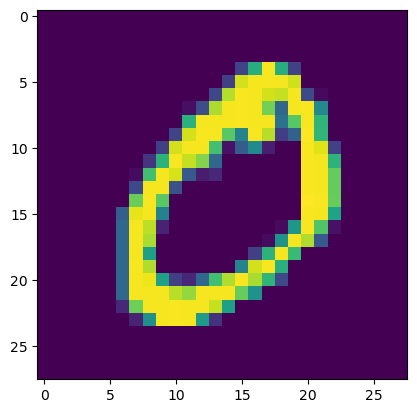

In [16]:
import matplotlib.pyplot as plt
plt.imshow(x_train[1])

In [17]:
x_train = x_train/255
x_text = x_test/255

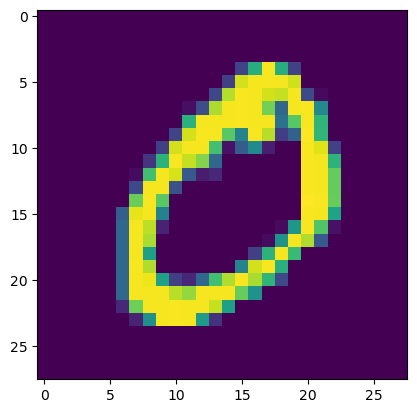

In [20]:
x_train[0]

In [22]:
model = Sequential()

model.add(Flatten(input_shape=(28,28)))
model.add(Dense(128 , activation="relu"))
model.add(Dense(32 , activation="relu"))
model.add(Dense(10 , activation='softmax'))

C:\Users\Abhishek sharma\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [37]:
model.compile(loss="sparse_categorical_crossentropy" , optimizer="Adam" , metrics=['accuracy'])
history = model.fit(x_train , y_train , epochs=20 , validation_split=0.2)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9988 - loss: 0.0043 - val_accuracy: 0.9763 - val_loss: 0.1224
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9986 - loss: 0.0046 - val_accuracy: 0.9760 - val_loss: 0.1447
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9988 - loss: 0.0034 - val_accuracy: 0.9762 - val_loss: 0.1372
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9984 - loss: 0.0056 - val_accuracy: 0.9744 - val_loss: 0.1518
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9986 - loss: 0.0041 - val_accuracy: 0.9768 - val_loss: 0.1348
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9984 - loss: 0.0051 - val_accuracy: 0.9778 - val_loss: 0.1336
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9991 - loss: 0.0039 - val_accuracy: 0.9793 - val_loss: 0.1238
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9996 - loss: 0.0018 -

In [38]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

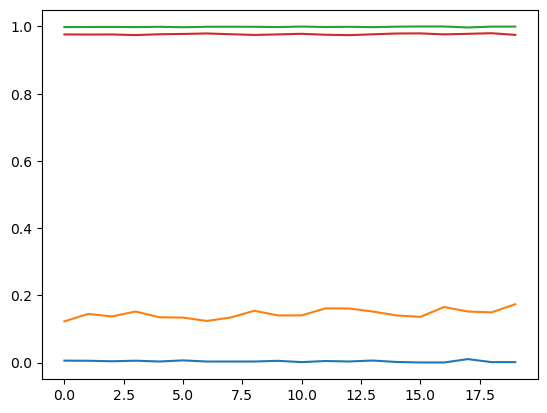

In [41]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

In [42]:
y_log = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [45]:
y_pred = y_log.argmax(axis=1)

In [46]:
y_pred

array([7, 2, 1, ..., 4, 5, 6], dtype=int64)

In [47]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test ,y_pred )

0.9747